<a href="https://colab.research.google.com/github/etoo-blip/Machine-Learning-Homework-4/blob/main/Homework_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# HOMEWORK 4
# PROBLEM 1: CANCER CLASSIFICATION USING SVM


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load the cancer dataset
cancer = pd.read_csv("Cancer.csv")

# Display the first five rows
cancer.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [2]:
# Check the dataset
print("Dataset shape:", cancer.shape)

print("\nDiagnosis counts:")
print(cancer["diagnosis"].value_counts())

print("\nMissing values:")
print(cancer.isnull().sum()[cancer.isnull().sum() > 0])

Dataset shape: (569, 33)

Diagnosis counts:
diagnosis
B    357
M    212
Name: count, dtype: int64

Missing values:
Unnamed: 32    569
dtype: int64


In [3]:
# Remove unnecessary columns
cancer_clean = cancer.drop(columns=["id", "Unnamed: 32"])

# Convert diagnosis to numerical values
cancer_clean["diagnosis"] = cancer_clean["diagnosis"].map({
    "B": 0,
    "M": 1
})

# Separate input features and target
X = cancer_clean.drop(columns=["diagnosis"])
Y = cancer_clean["diagnosis"]

# Split dataset: 80% training, 20% testing
# Same settings as Homework 3 for fair comparison
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=100,
    stratify=Y
)

print("Number of input features:", X.shape[1])
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(Y_train.value_counts())

print("\nTesting class distribution:")
print(Y_test.value_counts())

Number of input features: 30
Training samples: 455
Testing samples: 114

Training class distribution:
diagnosis
0    285
1    170
Name: count, dtype: int64

Testing class distribution:
diagnosis
0    72
1    42
Name: count, dtype: int64


In [4]:
# Standardize the input features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nFirst five standardized feature means:")
print(np.round(X_train_scaled.mean(axis=0)[:5], 4))

print("\nFirst five standardized feature standard deviations:")
print(np.round(X_train_scaled.std(axis=0)[:5], 4))

Training data shape: (455, 30)
Testing data shape: (114, 30)

First five standardized feature means:
[-0.  0.  0. -0.  0.]

First five standardized feature standard deviations:
[1. 1. 1. 1. 1.]


In [5]:
# Train SVM using a linear kernel
svm_linear = SVC(kernel="linear", C=1.0)

svm_linear.fit(X_train_scaled, Y_train)

# Make predictions on the test data
Y_pred_linear = svm_linear.predict(X_test_scaled)

# Calculate performance metrics
linear_accuracy = accuracy_score(Y_test, Y_pred_linear)
linear_precision = precision_score(Y_test, Y_pred_linear)
linear_recall = recall_score(Y_test, Y_pred_linear)
linear_f1 = f1_score(Y_test, Y_pred_linear)

print("SVM - Linear Kernel Results")
print("----------------------------")
print(f"Accuracy:  {linear_accuracy:.4f}")
print(f"Precision: {linear_precision:.4f}")
print(f"Recall:    {linear_recall:.4f}")
print(f"F1 Score:  {linear_f1:.4f}")

SVM - Linear Kernel Results
----------------------------
Accuracy:  0.9561
Precision: 0.9512
Recall:    0.9286
F1 Score:  0.9398


In [6]:
# Train SVM using Polynomial kernel
svm_poly = SVC(kernel="poly", degree=3, C=1.0)
svm_poly.fit(X_train_scaled, Y_train)

Y_pred_poly = svm_poly.predict(X_test_scaled)

# Train SVM using RBF kernel
svm_rbf = SVC(kernel="rbf", C=1.0)
svm_rbf.fit(X_train_scaled, Y_train)

Y_pred_rbf = svm_rbf.predict(X_test_scaled)

# Compare all three kernels
kernel_results = pd.DataFrame({
    "Kernel": ["Linear", "Polynomial", "RBF"],
    "Accuracy": [
        accuracy_score(Y_test, Y_pred_linear),
        accuracy_score(Y_test, Y_pred_poly),
        accuracy_score(Y_test, Y_pred_rbf)
    ],
    "Precision": [
        precision_score(Y_test, Y_pred_linear),
        precision_score(Y_test, Y_pred_poly),
        precision_score(Y_test, Y_pred_rbf)
    ],
    "Recall": [
        recall_score(Y_test, Y_pred_linear),
        recall_score(Y_test, Y_pred_poly),
        recall_score(Y_test, Y_pred_rbf)
    ],
    "F1 Score": [
        f1_score(Y_test, Y_pred_linear),
        f1_score(Y_test, Y_pred_poly),
        f1_score(Y_test, Y_pred_rbf)
    ]
})

print("SVM Kernel Comparison")
print(kernel_results.round(4).to_string(index=False))

SVM Kernel Comparison
    Kernel  Accuracy  Precision  Recall  F1 Score
    Linear    0.9561     0.9512  0.9286    0.9398
Polynomial    0.8772     1.0000  0.6667    0.8000
       RBF    1.0000     1.0000  1.0000    1.0000


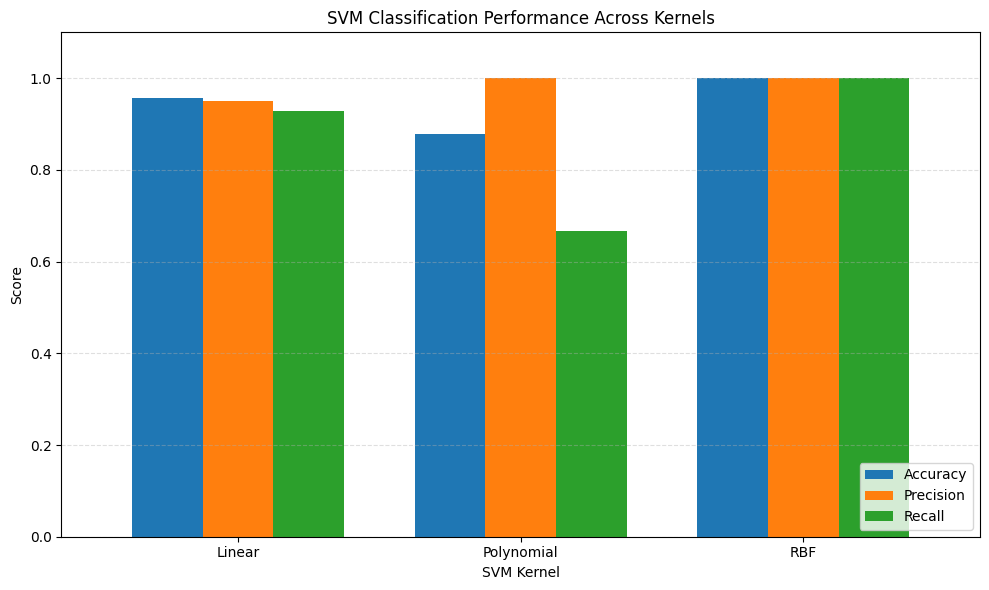

In [7]:
# Plot classification metrics for different kernels
ax = kernel_results.plot(
    x="Kernel",
    y=["Accuracy", "Precision", "Recall"],
    kind="bar",
    figsize=(10, 6),
    rot=0,
    width=0.75
)

plt.title("SVM Classification Performance Across Kernels")
plt.xlabel("SVM Kernel")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression    0.9649     0.9318  0.9762    0.9535
       SVM - Linear    0.9561     0.9512  0.9286    0.9398
   SVM - Polynomial    0.8772     1.0000  0.6667    0.8000
          SVM - RBF    1.0000     1.0000  1.0000    1.0000


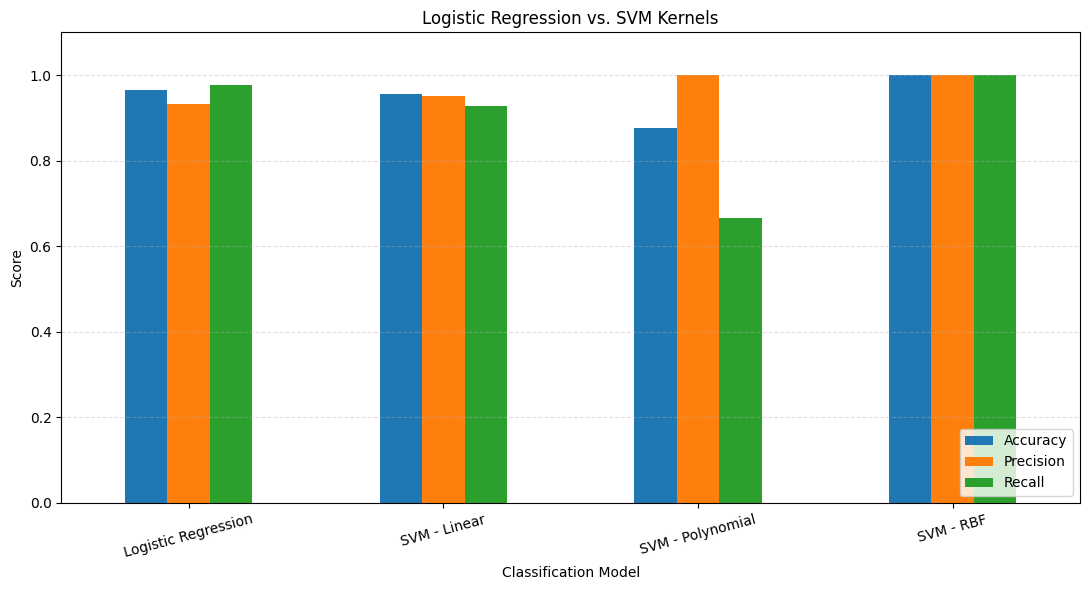

In [8]:
# Homework 3 logistic regression results
logistic_results = {
    "Model": "Logistic Regression",
    "Accuracy": 0.9649,
    "Precision": 0.9318,
    "Recall": 0.9762,
    "F1 Score": 0.9535
}

# Combine with Homework 4 SVM results
comparison = kernel_results.copy()
comparison = comparison.rename(columns={"Kernel": "Model"})
comparison["Model"] = "SVM - " + comparison["Model"]

comparison = pd.concat([
    pd.DataFrame([logistic_results]),
    comparison
], ignore_index=True)

print(comparison.round(4).to_string(index=False))

# Plot comparison
comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall"]
].plot(kind="bar", figsize=(11, 6), rot=15)

plt.title("Logistic Regression vs. SVM Kernels")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Five-fold cross-validation on training data only
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=100
)

from sklearn.pipeline import make_pipeline

rbf_pipeline = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0)
)

cv_scores = cross_val_score(
    rbf_pipeline,
    X_train,
    Y_train,
    cv=cv,
    scoring="accuracy"
)

print("RBF SVM Cross-Validation")
print("------------------------")
print("Fold accuracies:", np.round(cv_scores, 4))
print(f"Mean accuracy: {cv_scores.mean():.4f}")
print(f"Standard deviation: {cv_scores.std():.4f}")

RBF SVM Cross-Validation
------------------------
Fold accuracies: [0.967 0.978 0.978 0.956 0.967]
Mean accuracy: 0.9692
Standard deviation: 0.0082


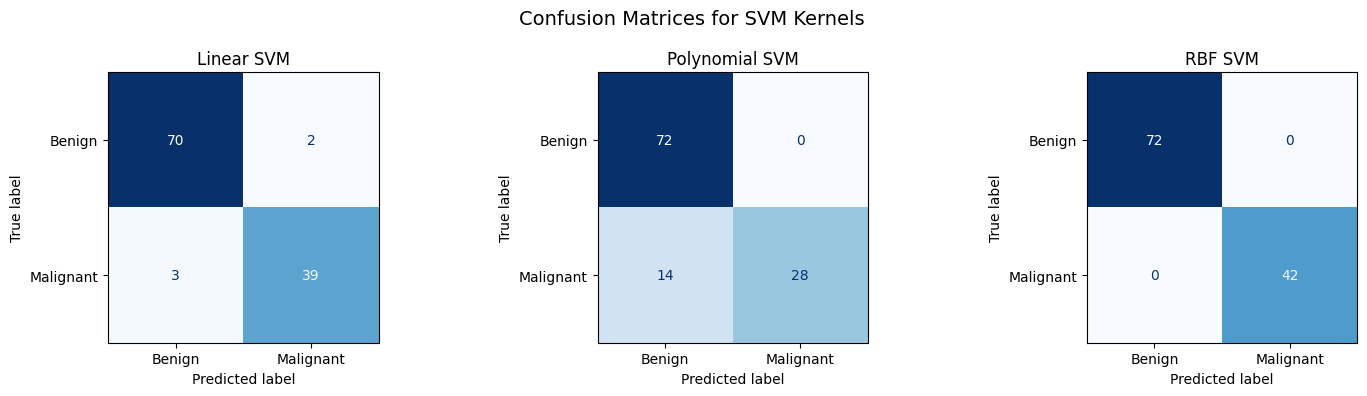

In [10]:
# Confusion matrices for the three SVM kernels

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

models = {
    "Linear SVM": Y_pred_linear,
    "Polynomial SVM": Y_pred_poly,
    "RBF SVM": Y_pred_rbf
}

for ax, (name, predictions) in zip(axes, models.items()):
    cm = confusion_matrix(Y_test, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.suptitle("Confusion Matrices for SVM Kernels", fontsize=14)
plt.tight_layout()
plt.show()

In [11]:

# PROBLEM 2
# HOUSING PRICE PREDICTION USING SVR


from sklearn.svm import SVR
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load housing dataset
housing = pd.read_csv("Housing.csv")

# Display first five rows
housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [12]:
# Check dataset structure
print("Dataset shape:", housing.shape)

print("\nColumn names:")
print(housing.columns.tolist())

print("\nMissing values:")
print(housing.isnull().sum())

print("\nFirst five records:")
print(housing.head())

Dataset shape: (545, 13)

Column names:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

Missing values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

First five records:
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes

In [13]:
# Select the 11 input features required
features = [
    "area", "bedrooms", "bathrooms", "stories",
    "mainroad", "guestroom", "basement",
    "hotwaterheating", "airconditioning",
    "parking", "prefarea"
]

# Separate inputs and target
X_house = housing[features].copy()
Y_house = housing["price"]

# Convert yes/no columns into 1/0
categorical_columns = [
    "mainroad", "guestroom", "basement",
    "hotwaterheating", "airconditioning", "prefarea"
]

for col in categorical_columns:
    X_house[col] = X_house[col].map({"yes": 1, "no": 0})

# Verify the cleaned data
print("Number of input features:", X_house.shape[1])
print("Missing values:", X_house.isnull().sum().sum())

print("\nFirst five rows:")
print(X_house.head())

Number of input features: 11
Missing values: 0

First five rows:
   area  bedrooms  bathrooms  stories  mainroad  guestroom  basement  \
0  7420         4          2        3         1          0         0   
1  8960         4          4        4         1          0         0   
2  9960         3          2        2         1          0         1   
3  7500         4          2        2         1          0         1   
4  7420         4          1        2         1          1         1   

   hotwaterheating  airconditioning  parking  prefarea  
0                0                1        2         1  
1                0                1        3         0  
2                0                0        2         1  
3                0                1        3         1  
4                0                1        2         0  


In [14]:
# Split housing dataset into 80% training and 20% testing
X_house_train, X_house_test, Y_house_train, Y_house_test = train_test_split(
    X_house,
    Y_house,
    test_size=0.2,
    random_state=100
)

print("Training samples:", X_house_train.shape[0])
print("Testing samples:", X_house_test.shape[0])

Training samples: 436
Testing samples: 109


In [15]:
# Standardize input features
house_scaler_X = StandardScaler()

X_house_train_scaled = house_scaler_X.fit_transform(X_house_train)
X_house_test_scaled = house_scaler_X.transform(X_house_test)

# Standardize target prices
house_scaler_Y = StandardScaler()

Y_house_train_scaled = house_scaler_Y.fit_transform(
    Y_house_train.to_numpy().reshape(-1, 1)
).ravel()

print("Training input shape:", X_house_train_scaled.shape)
print("Testing input shape:", X_house_test_scaled.shape)

print("\nFirst five feature means:")
print(np.round(X_house_train_scaled.mean(axis=0)[:5], 4))

print("\nFirst five feature standard deviations:")
print(np.round(X_house_train_scaled.std(axis=0)[:5], 4))

print("\nScaled target mean:",
      round(Y_house_train_scaled.mean(), 4))

Training input shape: (436, 11)
Testing input shape: (109, 11)

First five feature means:
[ 0.  0. -0.  0. -0.]

First five feature standard deviations:
[1. 1. 1. 1. 1.]

Scaled target mean: 0.0


In [16]:
# Train SVR using a linear kernel
svr_linear = SVR(
    kernel="linear",
    C=1.0,
    epsilon=0.1
)

svr_linear.fit(
    X_house_train_scaled,
    Y_house_train_scaled
)

# Predict scaled housing prices
Y_house_pred_linear_scaled = svr_linear.predict(
    X_house_test_scaled
)

# Convert predictions back to original price units
Y_house_pred_linear = house_scaler_Y.inverse_transform(
    Y_house_pred_linear_scaled.reshape(-1, 1)
).ravel()

# Calculate regression performance
linear_mae = mean_absolute_error(
    Y_house_test, Y_house_pred_linear
)

linear_rmse = np.sqrt(mean_squared_error(
    Y_house_test, Y_house_pred_linear
))

linear_r2 = r2_score(
    Y_house_test, Y_house_pred_linear
)

print("SVR - Linear Kernel Results")
print("----------------------------")
print(f"MAE:  {linear_mae:,.2f}")
print(f"RMSE: {linear_rmse:,.2f}")
print(f"R²:   {linear_r2:.4f}")

SVR - Linear Kernel Results
----------------------------
MAE:  776,082.75
RMSE: 1,069,445.77
R²:   0.6760


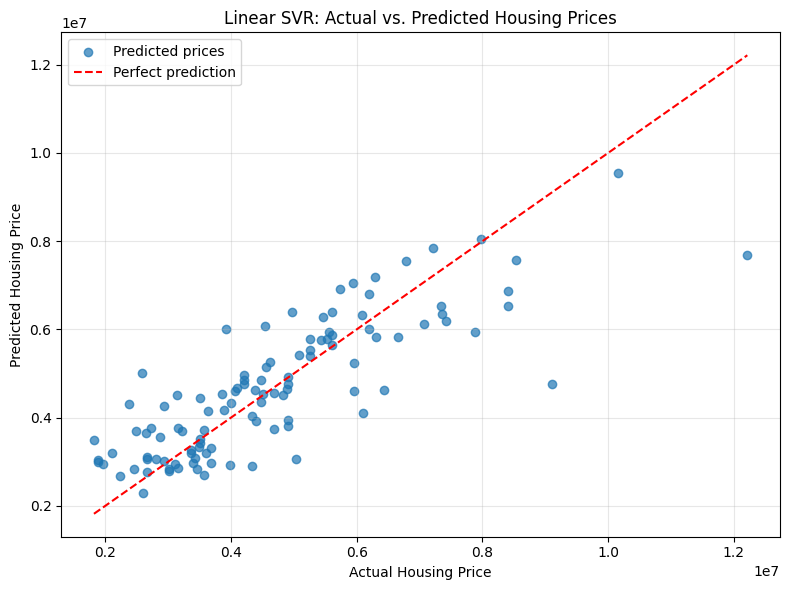

In [17]:
# Plot actual vs predicted housing prices
plt.figure(figsize=(8, 6))

plt.scatter(
    Y_house_test,
    Y_house_pred_linear,
    alpha=0.7,
    label="Predicted prices"
)

# Ideal prediction line
min_price = min(Y_house_test.min(), Y_house_pred_linear.min())
max_price = max(Y_house_test.max(), Y_house_pred_linear.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Housing Price")
plt.ylabel("Predicted Housing Price")
plt.title("Linear SVR: Actual vs. Predicted Housing Prices")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# TRAIN POLYNOMIAL AND RBF SVR MODELS

# Polynomial SVR
svr_poly = SVR(
    kernel="poly",
    degree=3,
    C=1.0,
    epsilon=0.1
)

svr_poly.fit(
    X_house_train_scaled,
    Y_house_train_scaled
)

# RBF SVR
svr_rbf = SVR(
    kernel="rbf",
    C=1.0,
    epsilon=0.1
)

svr_rbf.fit(
    X_house_train_scaled,
    Y_house_train_scaled
)

# Predict and convert back to original housing prices
Y_house_pred_poly = house_scaler_Y.inverse_transform(
    svr_poly.predict(X_house_test_scaled).reshape(-1, 1)
).ravel()

Y_house_pred_rbf = house_scaler_Y.inverse_transform(
    svr_rbf.predict(X_house_test_scaled).reshape(-1, 1)
).ravel()

# Compare regression performance
svr_results = []

predictions = {
    "Linear": Y_house_pred_linear,
    "Polynomial": Y_house_pred_poly,
    "RBF": Y_house_pred_rbf
}

for kernel, y_pred in predictions.items():

    mae = mean_absolute_error(Y_house_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(Y_house_test, y_pred)
    )

    r2 = r2_score(Y_house_test, y_pred)

    svr_results.append({
        "Kernel": kernel,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

svr_results = pd.DataFrame(svr_results)

print("SVR Kernel Comparison")
print(svr_results.round(4).to_string(index=False))

SVR Kernel Comparison
    Kernel         MAE         RMSE     R2
    Linear 776082.7464 1069445.7709 0.6760
Polynomial 941994.1524 1359475.0274 0.4764
       RBF 724736.5049 1062682.6237 0.6800


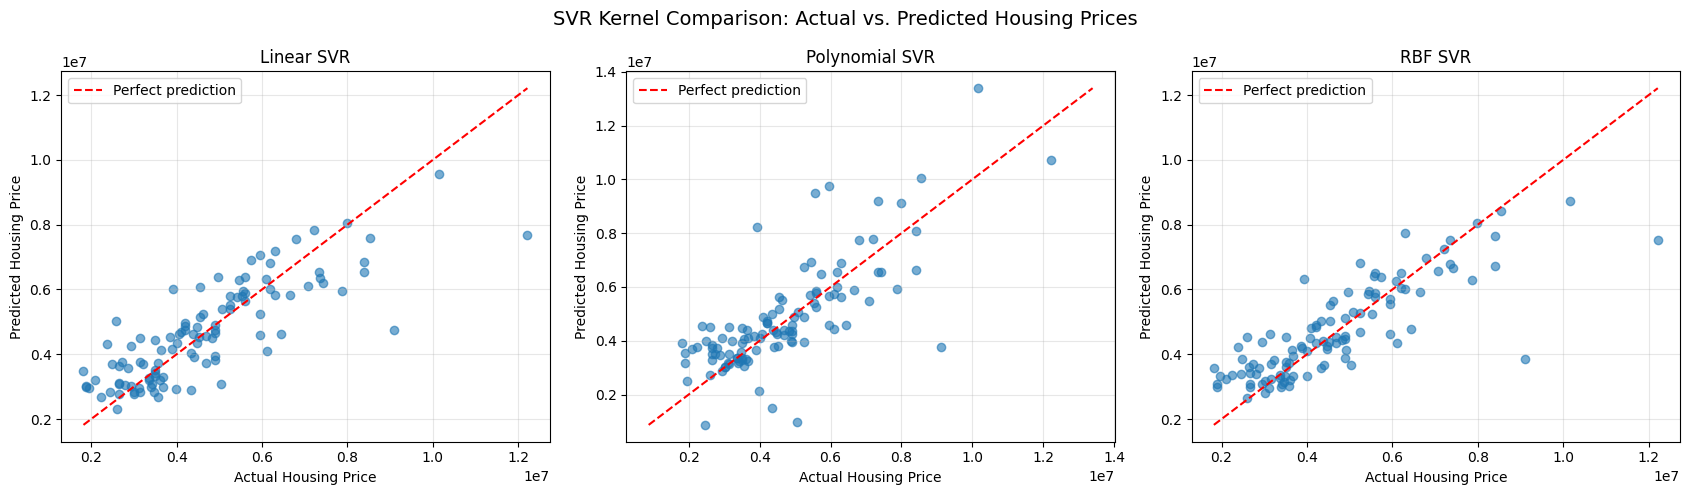

In [19]:
# Actual vs predicted prices for each SVR kernel

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (kernel, y_pred) in zip(axes, predictions.items()):

    ax.scatter(
        Y_house_test,
        y_pred,
        alpha=0.6
    )

    min_price = min(Y_house_test.min(), y_pred.min())
    max_price = max(Y_house_test.max(), y_pred.max())

    ax.plot(
        [min_price, max_price],
        [min_price, max_price],
        "r--",
        label="Perfect prediction"
    )

    ax.set_title(f"{kernel} SVR")
    ax.set_xlabel("Actual Housing Price")
    ax.set_ylabel("Predicted Housing Price")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "SVR Kernel Comparison: Actual vs. Predicted Housing Prices",
    fontsize=14
)

plt.tight_layout()
plt.show()

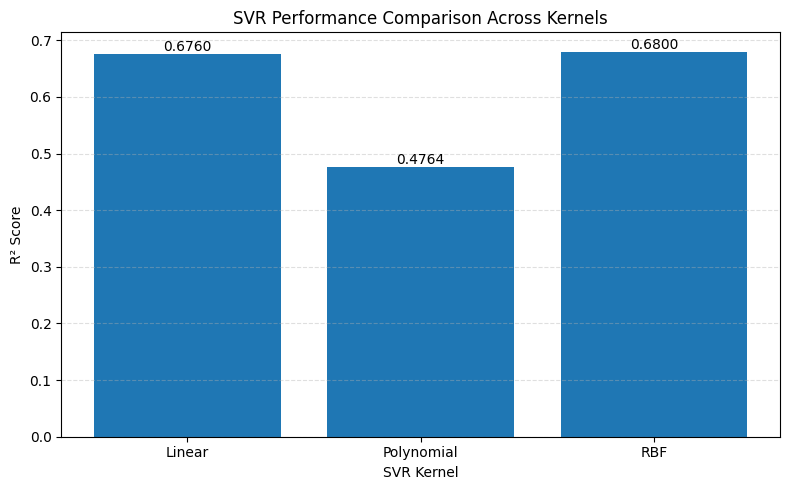

In [20]:
# Plot R2 scores for different SVR kernels

plt.figure(figsize=(8, 5))

bars = plt.bar(
    svr_results["Kernel"],
    svr_results["R2"]
)

plt.title("SVR Performance Comparison Across Kernels")
plt.xlabel("SVR Kernel")
plt.ylabel("R² Score")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [21]:
#REGULARIZED LINEAR REGRESSION COMPARISON
#

from sklearn.linear_model import Ridge

# Train regularized linear regression (L2 penalty)
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(
    X_house_train_scaled,
    Y_house_train_scaled
)

# Predict standardized housing prices
Y_house_pred_ridge_scaled = ridge_model.predict(
    X_house_test_scaled
)

# Convert predictions to original price units
Y_house_pred_ridge = house_scaler_Y.inverse_transform(
    Y_house_pred_ridge_scaled.reshape(-1, 1)
).ravel()

# Calculate performance metrics
ridge_mae = mean_absolute_error(
    Y_house_test, Y_house_pred_ridge
)

ridge_rmse = np.sqrt(mean_squared_error(
    Y_house_test, Y_house_pred_ridge
))

ridge_r2 = r2_score(
    Y_house_test, Y_house_pred_ridge
)

print("Regularized Linear Regression (Ridge)")
print("-------------------------------------")
print(f"MAE:  {ridge_mae:,.2f}")
print(f"RMSE: {ridge_rmse:,.2f}")
print(f"R²:   {ridge_r2:.4f}")

Regularized Linear Regression (Ridge)
-------------------------------------
MAE:  798,172.24
RMSE: 1,074,907.43
R²:   0.6726


Final Housing Price Prediction Comparison
          Kernel         MAE         RMSE     R2
Ridge Regression 798172.2402 1074907.4327 0.6726
          Linear 776082.7464 1069445.7709 0.6760
      Polynomial 941994.1524 1359475.0274 0.4764
             RBF 724736.5049 1062682.6237 0.6800


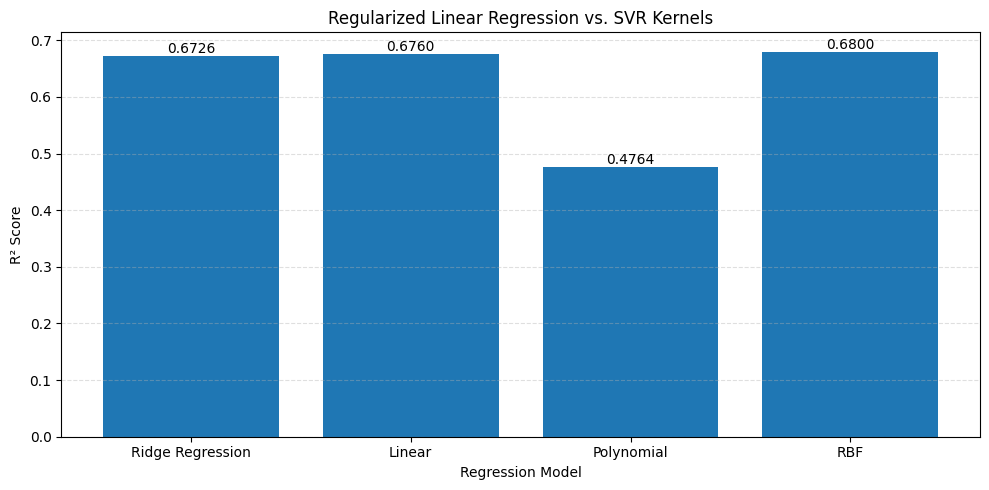

In [22]:
# Combine Ridge regression with SVR results
ridge_results = pd.DataFrame([{
    "Kernel": "Ridge Regression",
    "MAE": ridge_mae,
    "RMSE": ridge_rmse,
    "R2": ridge_r2
}])

final_results = pd.concat(
    [ridge_results, svr_results],
    ignore_index=True
)

print("Final Housing Price Prediction Comparison")
print(final_results.round(4).to_string(index=False))

# Plot R² comparison
plt.figure(figsize=(10, 5))

bars = plt.bar(
    final_results["Kernel"],
    final_results["R2"]
)

plt.title("Regularized Linear Regression vs. SVR Kernels")
plt.xlabel("Regression Model")
plt.ylabel("R² Score")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()